<a href="https://colab.research.google.com/github/purinpurin11/Granates/blob/Distancias/Distancias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()
archivo = next(iter(uploaded))
print("Archivo subido:", archivo)

Saving Granate.xlsx to Granate.xlsx
Archivo subido: Granate.xlsx


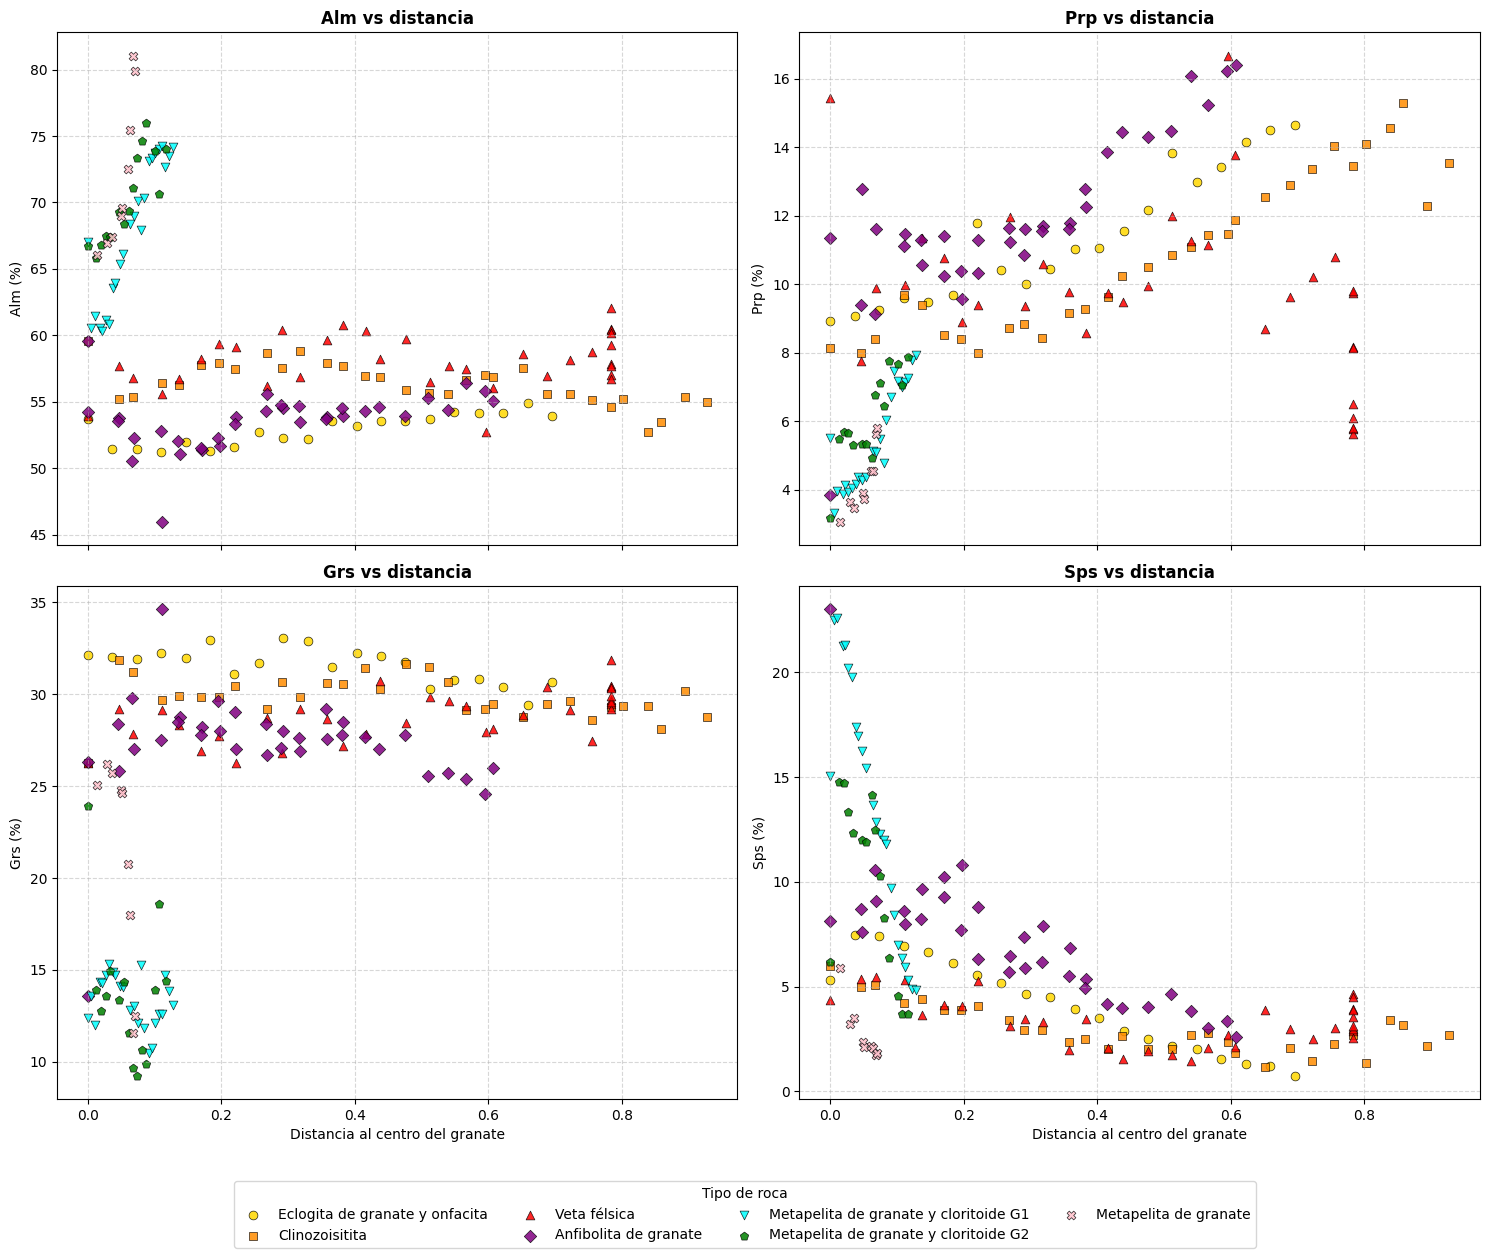

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# 1. Cargar la hoja
df = pd.read_excel(archivo, sheet_name="Diagrama distancias")
df.columns = [str(c).strip() for c in df.columns]

# 2. Buscar columnas (ignorando mayúsculas/acentos)
def buscar_col(patrones):
    for c in df.columns:
        c_clean = re.sub(r"[^a-z0-9]", "", c.lower())
        if any(p in c_clean for p in patrones):
            return c
    return None

col_dist = buscar_col(["distancia", "distance"])
col_alm = buscar_col(["alm", "almandino"])
col_prp = buscar_col(["prp", "piropo"])
col_grs = buscar_col(["grs", "grosular", "grossular"])
col_sps = buscar_col(["sps", "espessartina"])

# 3. Definir los rangos exactos de las muestras
muestras = {
    "Eclogita de granate y onfacita": (1, 21),
    "Clinozoisitita": (21, 52),
    "Veta félsica": (52, 86),
    "Anfibolita de granate": (86, 120),
    "Metapelita de granate y cloritoide G1": (120, 151),
    "Metapelita de granate y cloritoide G2": (151, 166),
    "Metapelita de granate": (166, 182)
}

# 4. Configurar nuevos estilos personalizados (colores solicitados)
estilos_muestras = {
    "Eclogita de granate y onfacita": {"color": "#FFD700", "marker": "o"},         # Amarillo
    "Clinozoisitita": {"color": "#FF8C00", "marker": "s"},                        # Naranja
    "Veta félsica": {"color": "#FF0000", "marker": "^"},                          # Rojo
    "Anfibolita de granate": {"color": "#800080", "marker": "D"},                 # Morado
    "Metapelita de granate y cloritoide G1": {"color": "#00FFFF", "marker": "v"}, # Azul cian
    "Metapelita de granate y cloritoide G2": {"color": "#008000", "marker": "p"}, # Verde
    "Metapelita de granate": {"color": "#FFC0CB", "marker": "X"}                  # Rosa
}

# 5. Configurar cuadrícula de subplots (2x2) para comparar todos pegados
fig, axes = plt.subplots(2, 2, figsize=(15, 12), sharex=True)
axes = axes.flatten()

endmembers = [
    (col_alm, "Alm", axes[0]),
    (col_prp, "Prp", axes[1]),
    (col_grs, "Grs", axes[2]),
    (col_sps, "Sps", axes[3])
]

for columna_em, nombre_em, ax in endmembers:
    for nombre, (inicio, fin) in muestras.items():
        sub_df = df.iloc[inicio:fin].copy()

        x = pd.to_numeric(sub_df[col_dist], errors="coerce")
        y = pd.to_numeric(sub_df[columna_em], errors="coerce")

        # Convertir a % si viene en fracción
        if y.dropna().max() <= 1.5:
            y = y * 100

        validos = x.notna() & y.notna()

        # Graficar los puntos en el subplot correspondiente
        ax.scatter(
            x[validos], y[validos],
            c=estilos_muestras[nombre]["color"],
            marker=estilos_muestras[nombre]["marker"],
            s=40, alpha=0.85, edgecolors='black', linewidth=0.5,
            label=nombre
        )

    # Títulos simplificados como se solicitó: "[Nombre] vs distancia"
    ax.set_title(f"{nombre_em} vs distancia", fontsize=12, fontweight="bold")
    ax.set_ylabel(f"{nombre_em} (%)", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)

# Añadir etiquetas de eje X solo a la fila inferior
axes[2].set_xlabel("Distancia al centro del granate", fontsize=10)
axes[3].set_xlabel("Distancia al centro del granate", fontsize=10)

# Colocar una leyenda unificada para toda la figura en la parte superior/derecha
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=4, title="Tipo de roca", frameon=True)

plt.tight_layout()
plt.subplots_adjust(bottom=0.08) # Espacio para la leyenda de abajo
plt.show()